In [1]:
import matplotlib.pyplot as plt
import numpy as np
from keras.models import Sequential
from keras.layers import Input, Dense
from keras.datasets import california_housing

(inputs, targets), (x_test, y_test) = california_housing.load_data(version='large', 
                                        test_split=0.2)
print(inputs.shape, targets.shape)
print(x_test.shape, y_test.shape)

2026-10-30 11:59:31.690411: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: SSE3 SSE4.1 SSE4.2 AVX AVX2 AVX512F AVX512_VNNI AVX512_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


(16512, 8) (16512,)
(4128, 8) (4128,)


In [2]:
# tarkastellaan jakoa
print(f"treenidatan prosentuaalinen koko: {inputs.shape[0] * 100 / (inputs.shape[0] + x_test.shape[0])}%")

print(f"testidatan prosentuaalinen koko: {x_test.shape[0] * 100 / (inputs.shape[0] + x_test.shape[0])}%")

treenidatan prosentuaalinen koko: 80.0%
testidatan prosentuaalinen koko: 20.0%


## Tarkastelaan mikä on noin 20% validointidataa varte

In [3]:
print(inputs.shape[0]*0.2)

3302.4


In [4]:
# Datan jako treeni ja validointi dataan

x_train = inputs[:3302]
y_train = targets[:3302]
x_val = inputs[3302:]
y_val = targets[3302:]

## Standardoidaan treenidata

In [5]:
# Keskiarvo ja keskihajonta lasketaan vain treenidatasta
mean = x_train.mean(axis=0)
std = x_train.std(axis=0)
x_train -= mean
x_train /= std
x_test -= mean
x_test /= std
x_val -= mean
x_val /= std

# Tarkastellaan 5 ensimmäistä tulosta
print(f"x_train: {x_train[:5]}\n")
print(f"\nx_test: {x_test[:5]}\n")
print(f"\n*x_val:{x_val[:5]}")

x_train: [[ 0.64686644 -0.726207    1.8460935  -0.14181662  0.02465125 -0.3227104
  -0.03514035 -0.0214899 ]
 [ 0.60193646 -0.7872896  -0.6165995  -0.37251514  0.02691749 -0.12917645
   0.12836713 -0.5960084 ]
 [-1.4098378   0.99818665  1.8460935  -0.3395582  -0.26542684 -0.5959348
  -0.26553726  0.08049081]
 [ 0.80661017 -0.8060845  -1.4110166   0.209724    0.36685273  0.12127924
   0.46776903  0.28195027]
 [-1.4747324   1.0733646  -0.37827438 -0.97936213 -1.0880702  -1.0423639
  -1.065733    5.851837  ]]


x_test: [[ 6.0193646e-01 -7.3090482e-01  1.2900015e+00 -1.9982082e-01
  -1.3851766e-01 -1.4625297e-01 -1.2432626e-01 -2.3812409e-01]
 [-3.1658918e-01 -4.7248095e-01 -1.1726915e+00 -1.2003747e-03
  -6.5998144e-02  3.4270279e-02 -4.2572513e-02  3.4139830e-01]
 [-8.2078195e-01  1.0216812e+00 -1.6493417e+00 -3.3692166e-01
  -5.5777115e-01 -3.6255562e-01 -5.0584370e-01  7.4448037e-01]
 [-1.2451010e+00  1.0404743e+00 -9.3436635e-01  2.1203473e+00
   2.2931526e+00  5.2623683e-01  2.338195

In [6]:
# Tarkastellaan kohdearvoja (10 ensimmäistä)
print(f"y_train (10 ensimmäistä):\n{y_train[:10]}\n")
print(f"y_test (10 ensimmäistä):\n{y_test[:10]}\n")
print(f"y_val (10 ensimmäistä):\n{y_val[:10]}")

y_train (10 ensimmäistä):
[252300. 146900. 290900. 141300. 500001.  72000. 252400. 162500. 500001.
 226800.]

y_test (10 ensimmäistä):
[397900. 227900. 172100. 186500. 148900.  65600. 344600. 235600. 233000.
 192100.]

y_val (10 ensimmäistä):
[228900.  71900. 272200. 395300. 316700. 177500. 500000. 267500. 105100.
 339700.]


In [7]:
# arvot ovat 100 tuhansissa tai lähellä -> jaetaan 100000:lla
y_train /= 1e5
y_test /= 1e5
y_val /= 1e5

# Tarkastellaan kohdearvoja jaon jälkeen (10 ensimmäistä)
print(f"y_train (10 ensimmäistä):\n{y_train[:10]}\n")
print(f"y_test (10 ensimmäistä):\n{y_test[:10]}\n")
print(f"y_val (10 ensimmäistä):\n{y_val[:10]}\n")

y_train (10 ensimmäistä):
[2.523   1.469   2.909   1.413   5.00001 0.72    2.524   1.625   5.00001
 2.268  ]

y_test (10 ensimmäistä):
[3.979 2.279 1.721 1.865 1.489 0.656 3.446 2.356 2.33  1.921]

y_val (10 ensimmäistä):
[2.289 0.719 2.722 3.953 3.167 1.775 5.    2.675 1.051 3.397]



## Baseline mallin rakennus ja koulutus

In [8]:
# Baseline malli, ilman ylisovittamisen tuontia
model_baseline = Sequential([
    Input(shape=(8,)),
    Dense(128, activation='relu'),
    Dense(128, activation='relu'),
    Dense(64, activation='relu'),
    Dense(1)
])

# configure the learning algorithm
model_baseline.compile(optimizer='adam',loss='mse',metrics=['mae'])

I0000 00:00:1793354374.451066  168233 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 21760 MB memory:  -> device: 0, name: AMD Radeon RX 7900 XTX, pci bus id: 0000:03:00.0


In [9]:
# Ekan ajon 500 epoch huomasin että 300 epochia riitti jo todistamaan ylisovituksen.
histories = {}

epochs = 300

histories["Baseline malli"] = model_baseline.fit(x_train, y_train, epochs=epochs, batch_size=32, validation_data=(x_val, y_val), verbose=0)

2026-10-30 11:59:36.190301: I external/local_xla/xla/service/service.cc:163] XLA service 0x7b28780084e0 initialized for platform ROCM (this does not guarantee that XLA will be used). Devices:
2026-10-30 11:59:36.190321: I external/local_xla/xla/service/service.cc:171]   StreamExecutor device (0): AMD Radeon RX 7900 XTX, AMDGPU ISA version: gfx1100
2026-10-30 11:59:36.204514: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
2026-10-30 11:59:36.297700: I external/local_xla/xla/service/gpu/autotuning/dot_search_space.cc:208] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
2026-10-30 11:59:36.297729: I external/local_xla/xla/service/gpu/autotuning/dot_search_space.cc:208] All configs were filtered out because none o

## Baseline-mallin valinta

Aluksi kokeilin erilaisia neuroverkkoarkkitehtuureja ilman regularisointia. Kokeilin ensin pienempää mallia, jossa oli kaksi piilokerrosta (32 ja 16 neuronia), sekä suurempaa mallia, jossa oli kolme piilokerrosta (64, 64 ja 32 neuronia).

Tämän jälkeen kokeilin vielä kolmea suurempaa mallia, joiden piilokerroksissa oli 128/128/64, 256/256/128 ja 512/256/128/64 neuronia.

Lopulta valitsin 128/128/64-mallin, koska siinä ylisovittuminen näkyi erittäin selvästi. Malli oli myös kevyempi kouluttaa kuin kaksi suurinta mallia.

## L2 reguloimalla ylisovittamisen estäminen

In [10]:
from keras.regularizers import l2

# L2 0.001
model_L2_0001 = Sequential([
    Input(shape=(8,)),
    Dense(128, activation='relu', kernel_regularizer=l2(0.001)),
    Dense(128, activation='relu', kernel_regularizer=l2(0.001)),
    Dense(64, activation='relu', kernel_regularizer=l2(0.001)),
    Dense(1)
])

model_L2_0001.compile(optimizer='adam', loss='mse', metrics=['mae'])

histories["L2 0.001"] = model_L2_0001.fit(x_train, y_train, epochs=epochs, batch_size=32, validation_data=(x_val, y_val), verbose=0)

## Johtopäätökset

Huomasin, että L2-regularisoinnin pienentäminen eli painokertoimien rankaisun vähentäminen lisäsi ylisovittamista. Testasin arvoja 0.0001, 0.001 ja 0.01. Pienimmällä arvolla training loss jatkoi laskuaan, vaikka validation loss alkoi kasvaa. Suurimmalla arvolla 0.01 regularisointi oli puolestaan liian voimakasta ja rajoitti mallin oppimista.

Valitsin jatkoon L2-arvon 0.001, koska sillä saavutettiin paras validation MAE (0.3579). Ylisovittamista oli edelleen havaittavissa, mutta huomattavasti vähemmän kuin reguloimattomalla baseline-mallilla.

Poistin muiden L2-arvojen koulutukset jatkokokeiluista havaintojen jälkeen.

## Dropout

Kokeillaan dropourir arvoilla 0.1, 0.2 ja 0.3 ja pidetään taas vain paras/lupaavin tulos.

In [11]:
from keras.layers import Dropout

# Dropout 10 %
model_D1 = Sequential([
    Input(shape=(8,)),
    Dense(128, activation='relu'),
    Dropout(0.1),
    Dense(128, activation='relu'),
    Dropout(0.1),
    Dense(64, activation='relu'),
    Dropout(0.1),
    Dense(1)
])

model_D1.compile(optimizer='adam', loss='mse', metrics=['mae'])

histories["Dropout 10%"] = model_D1.fit(x_train, y_train, epochs=epochs, batch_size=32, validation_data=(x_val, y_val), verbose=0)

2026-10-30 12:21:36.690549: I external/local_xla/xla/service/gpu/autotuning/dot_search_space.cc:208] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
2026-10-30 12:21:36.690587: I external/local_xla/xla/service/gpu/autotuning/dot_search_space.cc:208] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
2026-10-30 12:21:36.690591: I external/local_xla/xla/service/gpu/autotuning/dot_search_space.cc:208] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.


## Dropout-johtopäätökset

Testasin Dropout-regularisointia arvoilla 0.1, 0.2 ja 0.3. Pienimmällä arvolla ylisovittamista esiintyi edelleen selvästi, sillä training loss jatkoi laskuaan validation lossin alkaessa kasvaa. Suuremmilla Dropout-arvoilla validation loss pysyi tasaisempana koulutuksen loppupuolella, mikä viittaa ylisovittamisen vähenemiseen.

Parhaan validation MAE:n saavutti Dropout 0.1 (0.3577) 82. epochilla. Dropout 0.3 saavutti MAE-arvon 0.3609 ja Dropout 0.2 arvon 0.3624. Erot olivat melko pieniä, mutta voimakkaampi Dropout ei siis parantanut MAE-tulosta.

Valitsin jatkoon Dropout 0.1 -mallin, koska se saavutti pienimmän validation MAE:n. Dropout 0.3 vähensi kuitenkin ylisovittamisen merkkejä kuvaajien perusteella enemmän, vaikka sen MAE oli hieman heikompi.

## BatchNormalization kokeilu

Kokeillaan miten BatchNormalization vaikuttaa. Kokeilen jos lisään vain yhteen, kahteen tai kaikkiin kolmeen kerrokseen. Testasin vain ekan tason normalisointia, ekan ja tokan, sekä kaikkien tasojen normalisointia.

In [12]:
from keras.layers import BatchNormalization

# BatchNormalization 3 kerrosta
model_BN3 = Sequential([
    Input(shape=(8,)),
    Dense(128, activation='relu'),
    BatchNormalization(),
    Dense(128, activation='relu'),
    BatchNormalization(),
    Dense(64, activation='relu'),
    BatchNormalization(),
    Dense(1)
])

model_BN3.compile(optimizer='adam', loss='mse', metrics=['mae'])

histories["BatchNormalization 3 BN"] = model_BN3.fit(x_train, y_train, epochs=epochs, batch_size=32, validation_data=(x_val, y_val), verbose=0)

2026-10-30 12:38:16.898226: I external/local_xla/xla/service/gpu/autotuning/dot_search_space.cc:208] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
2026-10-30 12:43:50.310245: I external/local_xla/xla/service/gpu/autotuning/dot_search_space.cc:208] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.


## BatchNormalization-johtopäätökset

BatchNormalization-käyrien perusteella parhaan tuloksen saavutti kolmen kerroksen normalisointi, jonka validation MAE oli 0.3707. Paras tulos saavutettiin 94. epochilla. Kahden kerroksen normalisoinnilla MAE oli 0.3731 ja yhden kerroksen normalisoinnilla 0.3744.

Kuvaajien perusteella BatchNormalization vähensi ylisovittamisen merkkejä baseline-malliin verrattuna, sillä validation loss pysyi melko tasaisena koulutuksen edetessä. Kaikilla kolmella mallilla training loss kuitenkin jatkoi laskuaan validation lossin pysyessä lähes muuttumattomana, joten ylisovittamista esiintyi edelleen. (Kuvaajat poistui, kun uudelleen ajoin notebookin, josta hylätyt mallit)

Pelkkä BatchNormalization ei siis poistanut ylisovittamista eikä parantanut parasta MAE-tulosta baseline-malliin verrattuna (0.3699). Seuraavaksi kokeilen eri regularisointimenetelmien yhdistelmiä. Näistä kolmesta mallista valitsin jatkoon kolmen kerroksen normalisoinnin, koska se saavutti pienimmän validation MAE:n.

## Yhdistelmäkokeilut

Selvästi vähiten ylioppimista vähensi BatchNormalisation. Siksi en erikseen testaa sitä yksinään vaan testaan mallit: L2 0.001 + DropOut 10%, L2 0.001 + BatchNormalization 3 BN, DropOut 10% + BatchNormalization 3 BN ja kaikki 3 eli L2 0.001 + DropOut 10% + BatchNormalization 3 BN.

In [17]:
# L2 0.001 + DropOut 10%
epochs = 300

model_L2_D1 = Sequential([
    Input(shape=(8,)),
    Dense(128, activation='relu', kernel_regularizer=l2(0.001)),
    Dropout(0.1),
    Dense(128, activation='relu', kernel_regularizer=l2(0.001)),
    Dropout(0.1),
    Dense(64, activation='relu', kernel_regularizer=l2(0.001)),
    Dropout(0.1),
    Dense(1)
])

model_L2_D1.compile(optimizer='adam', loss='mse', metrics=['mae'])

histories["L2 0.001 + DropOut 10%"] = model_L2_D1.fit(x_train, y_train, epochs=epochs, batch_size=32, validation_data=(x_val, y_val), verbose=0)


# L2 0.001 + BatchNormalization 3 BN
model_L2_BN3 = Sequential([
    Input(shape=(8,)),
    Dense(128, activation='relu', kernel_regularizer=l2(0.001)),
    BatchNormalization(),
    Dense(128, activation='relu', kernel_regularizer=l2(0.001)),
    BatchNormalization(),
    Dense(64, activation='relu', kernel_regularizer=l2(0.001)),
    BatchNormalization(),
    Dense(1)
])

model_L2_BN3.compile(optimizer='adam', loss='mse', metrics=['mae'])

histories["L2 0.001 + BatchNormalization 3 BN"] = model_L2_BN3.fit(x_train, y_train, epochs=epochs, batch_size=32, validation_data=(x_val, y_val), verbose=0)


# DropOut 10% + BatchNormalization 3 BN
model_D1_BN3 = Sequential([
    Input(shape=(8,)),
    Dense(128, activation='relu'),
    BatchNormalization(),
    Dropout(0.1),
    Dense(128, activation='relu'),
    BatchNormalization(),
    Dropout(0.1),
    Dense(64, activation='relu'),
    BatchNormalization(),
    Dropout(0.1),
    Dense(1)
])

model_D1_BN3.compile(optimizer='adam', loss='mse', metrics=['mae'])

histories["DropOut 10% + BatchNormalization 3 BN"] = model_D1_BN3.fit(x_train, y_train, epochs=epochs, batch_size=32, validation_data=(x_val, y_val), verbose=0)


# L2 0.001 + DropOut 10% + BatchNormalization 3 BN
model_L2_D1_BN3 = Sequential([
    Input(shape=(8,)),
    Dense(128, activation='relu', kernel_regularizer=l2(0.001)),
    BatchNormalization(),
    Dropout(0.1),
    Dense(128, activation='relu', kernel_regularizer=l2(0.001)),
    BatchNormalization(),
    Dropout(0.1),
    Dense(64, activation='relu', kernel_regularizer=l2(0.001)),
    BatchNormalization(),
    Dropout(0.1),
    Dense(1)
])

model_L2_D1_BN3.compile(optimizer='adam', loss='mse', metrics=['mae'])

histories["L2 0.001 + DropOut 10% + BatchNormalization 3 BN"] = model_L2_D1_BN3.fit(x_train, y_train, epochs=epochs, batch_size=32, validation_data=(x_val, y_val), verbose=0)


## Yhdistelmö johtopäätökset

Kaikkien kolmen yhdistelmän malli sai tasaisimman käyrän, mutta jäi val MAE loss arvolla jälkeen mitä aikaisempia malleja (Val MAE 3 yhdistelmälle: 0.3634, pelkkä L2 0.001: 03551, L2 0.001 + DropOut 10% 0,3536). Arvot parhaimpaan malliin MAE verraten jää vain 0,0098 eli 980 dollaria. Mallin treeni ja validaatio lossien käyrät ovat lähes päällekkäin ja käyrät (treeni että validaatio) ovat lähes suoria viivoja. Pelkkää val MAE loss arvoa seuraten malli L2 0.001 + DropOut 10% on paras mutta käyrien ja erojen perusteella kolmen yhdistelmä on paras.

## EarlyStopping

Kokeillaan näitä kahta, L2 0.001 + DropOut 10% + BatchNormalization 3 BN ja L2 0.001 + DropOut 10%, vielä EarlyStopperilla. Patience on 40 ja monitoroidaan val_mae:a. Asetetaan max epochs 1000, jotta saadaan todellinen lopputulema.

In [20]:
from keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(
    monitor='val_mae',
    patience=40,
    mode='min',
    restore_best_weights=True # Palauttaa parhaat painot pysäytyksen jälkeen.
)

In [21]:
epochs = 1000

# L2 0.001 + DropOut 10% + BatchNormalization 3 BN + EarlyStopping
model_L2_D1_BN3_ES = Sequential([
    Input(shape=(8,)),
    Dense(128, activation='relu', kernel_regularizer=l2(0.001)),
    BatchNormalization(),
    Dropout(0.1),
    Dense(128, activation='relu', kernel_regularizer=l2(0.001)),
    BatchNormalization(),
    Dropout(0.1),
    Dense(64, activation='relu', kernel_regularizer=l2(0.001)),
    BatchNormalization(),
    Dropout(0.1),
    Dense(1)
])

model_L2_D1_BN3_ES.compile(optimizer='adam', loss='mse', metrics=['mae'])

histories["L2 0.001 + DropOut 10% + BatchNormalization 3 BN + EarlyStopping"] = model_L2_D1_BN3_ES.fit(x_train, y_train, epochs=epochs, batch_size=32, validation_data=(x_val, y_val), callbacks=[early_stopping], verbose=0)


# L2 0.001 + DropOut 10% + EarlyStopping
model_L2_D1_ES = Sequential([
    Input(shape=(8,)),
    Dense(128, activation='relu', kernel_regularizer=l2(0.001)),
    Dropout(0.1),
    Dense(128, activation='relu', kernel_regularizer=l2(0.001)),
    Dropout(0.1),
    Dense(64, activation='relu', kernel_regularizer=l2(0.001)),
    Dropout(0.1),
    Dense(1)
])

model_L2_D1_ES.compile(optimizer='adam', loss='mse', metrics=['mae'])

histories["L2 0.001 + DropOut 10% + EarlyStopping"] = model_L2_D1_ES.fit(x_train, y_train, epochs=epochs, batch_size=32, validation_data=(x_val, y_val), callbacks=[early_stopping], verbose=0)

## Johtopäätökset

Aikaisemmin parhaaksi malliksi valitulla L2 0.001 + DropOut 10% mallilla pysäytettiin koulutus hieman aikaisemmin ja validaatio MAE loss arvo heikkeni 0,0054 (|0,3590 - 0,3536|). Ero on on pieni ja koulutusaika on huomattavasti parempi. Joten early stopping paransi koulutusaikaa heikentämällä val MAE arvoa. EarlyStoppingilla val ja train erot olivat ilman: 0,0001 (|0,3536 - 0,3535|) ja pysäyttimellä: 0,0028 (|0,3590 - 0,3562|). Näiden erotus välinen ero oli vain 0,0027. 

Toiseksi testiin valitulla kolmen regularisointimenetelmän mallilla L2 0.001 + DropOut 10% + BatchNormalization 3 BN EarlyStopping pysäytti koulutuksen aikaisemmin, mutta validaatio MAE -arvo heikkeni 0,0064 (|0,3698 - 0,3634|). Ero oli siis hieman suurempi kuin ensimmäisellä mallilla. EarlyStoppingilla val ja train MAE erot olivat ilman: 0,0292 (|0,3634 - 0,3926|) ja pysäyttimellä: 0,0283 (|0,3698 - 0,3981|). Näiden erotusten välinen ero oli vain 0,0009 (|0,0292 - 0,0283|). EarlyStopping siis pienensi hieman koulutus- ja validaatio-MAE välistä eroa sekä lyhensi koulutusta, mutta heikensi validaatio MAE -arvoa.

EarlyStopping siis tehostaa kouluttamista, mutta muuttaa hieman val MAE arvoa laskien keskimäärin. Val ja train MAE erotukset parani 3 regulointi menetelmän mallissa, mutta val MAE jää matalaksi. Sen voi siis poissulkea. Val ja train MAE erotukset heikkeni L2 0.001 + DropOut 10% mallilla pysäyttimen kanssa ja myös paras val MAE laski hieman. Mutta pysäytin takaa ettei malli yliopi ja se heikensi vain erotusta pienellä. Samalla koulutusaika parani. Eli L2 0.001 + DropOut 10% malli EarlyStoppingilla on siis ylioppimisen mukaan paras malli.

## Kaikkien paitsi eri Baseline mallien koulutuskäyrät

Jätin nämä tänne perustelujen selkeyttämiseksi. Poisitin koulutetut mallit ylläolevista koodeista.

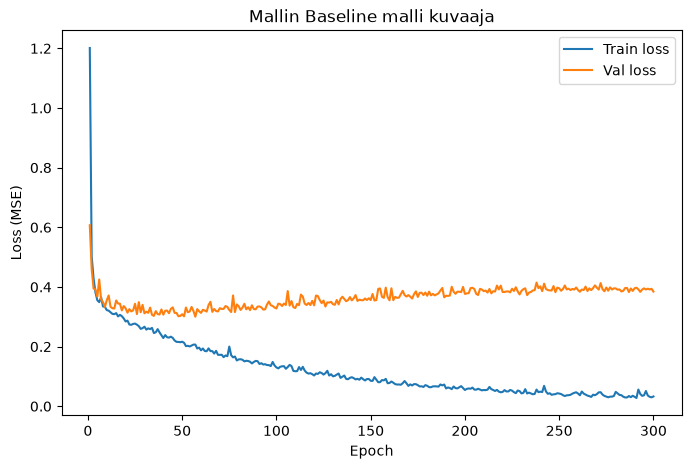

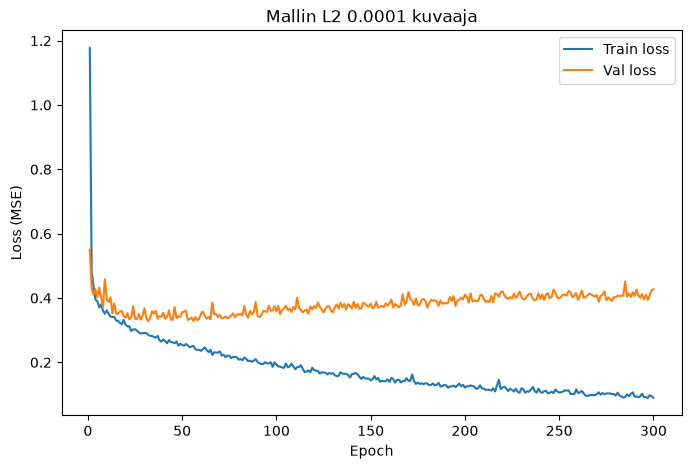

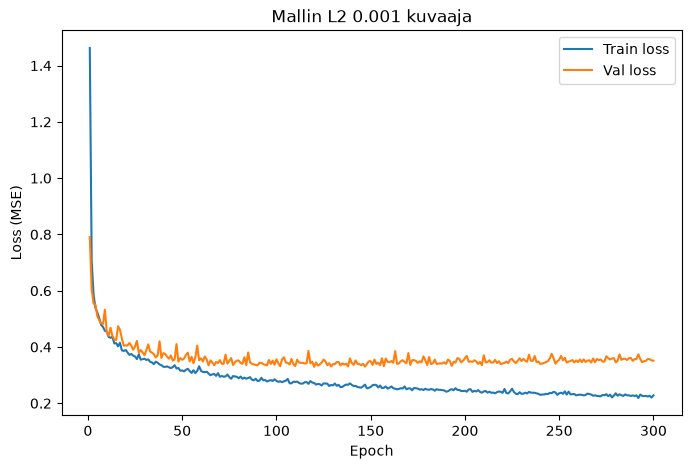

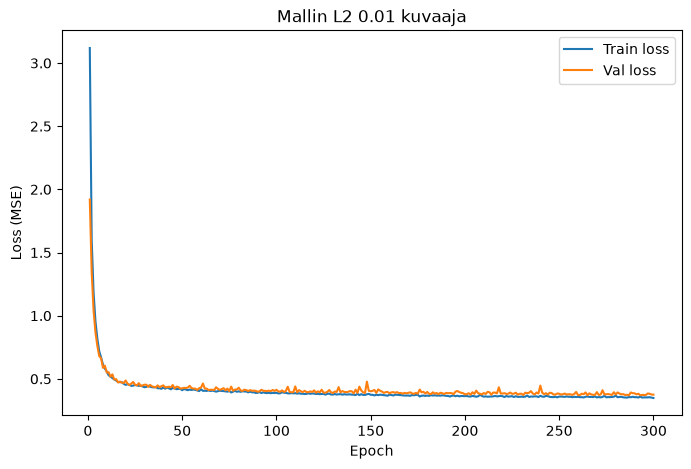

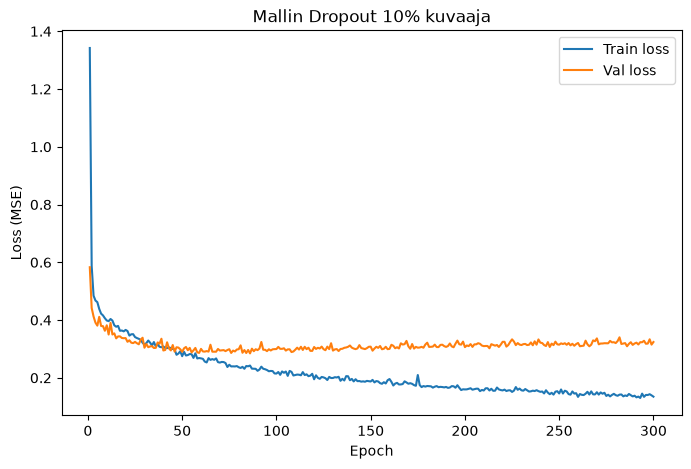

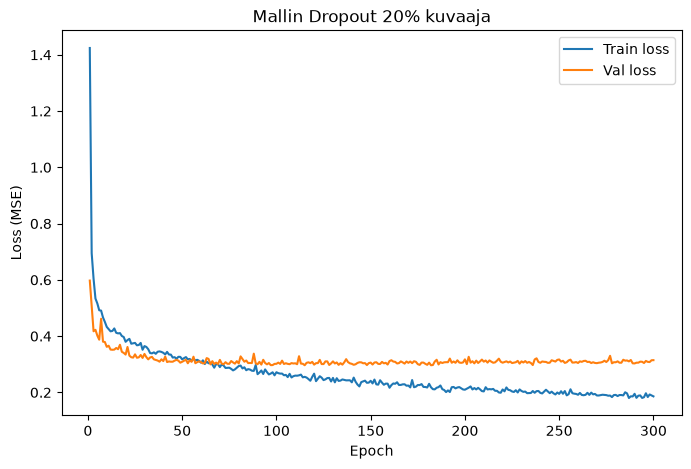

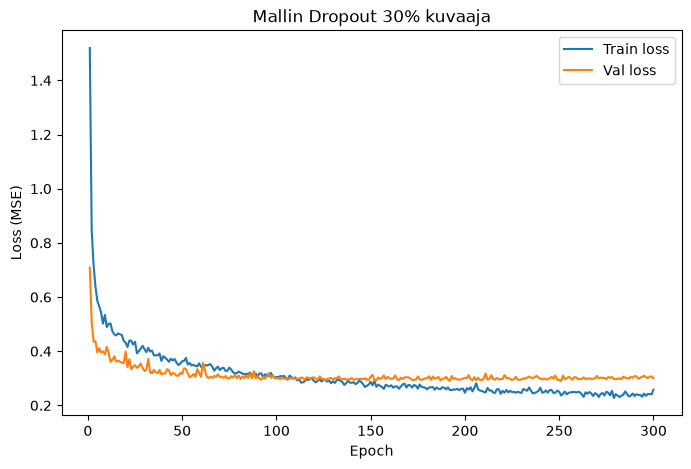

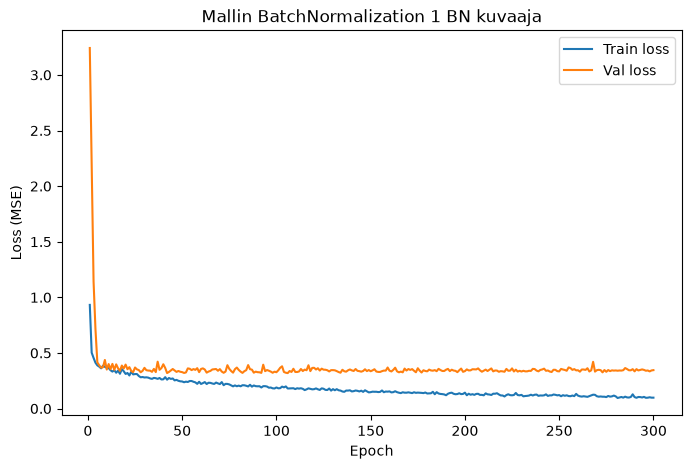

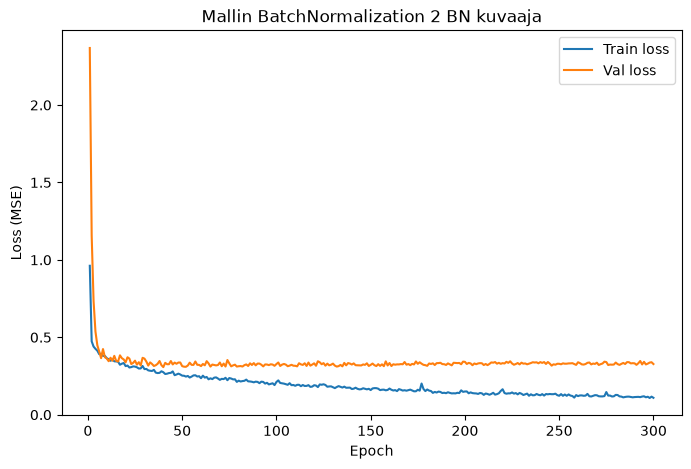

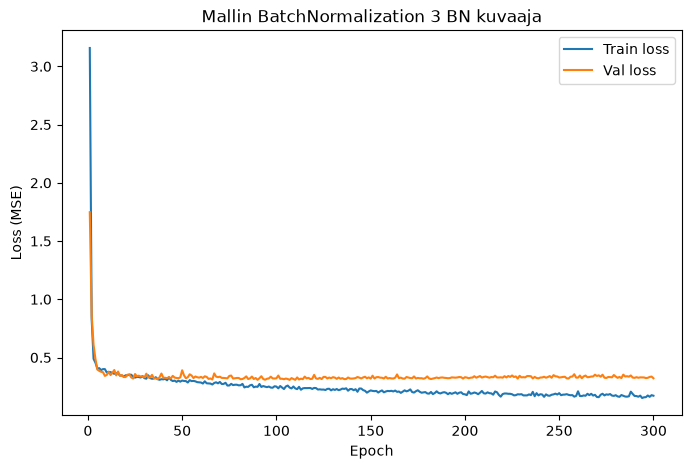

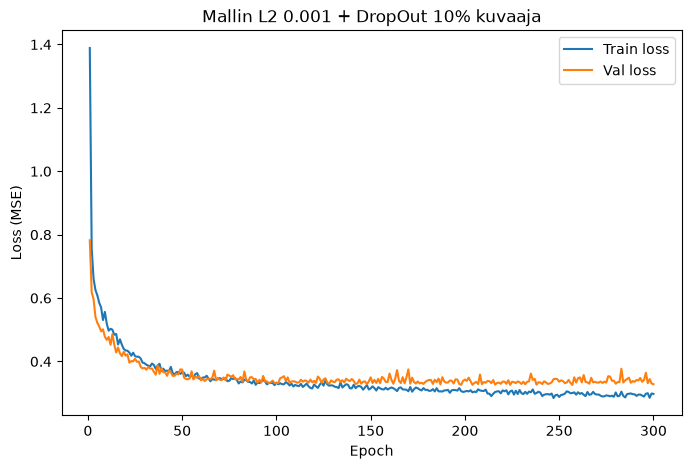

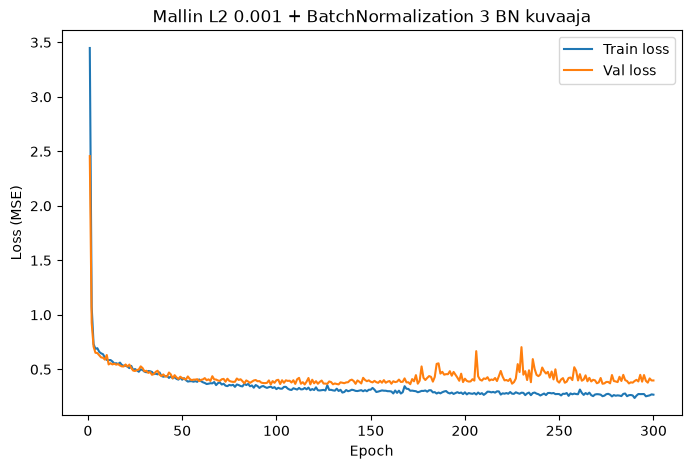

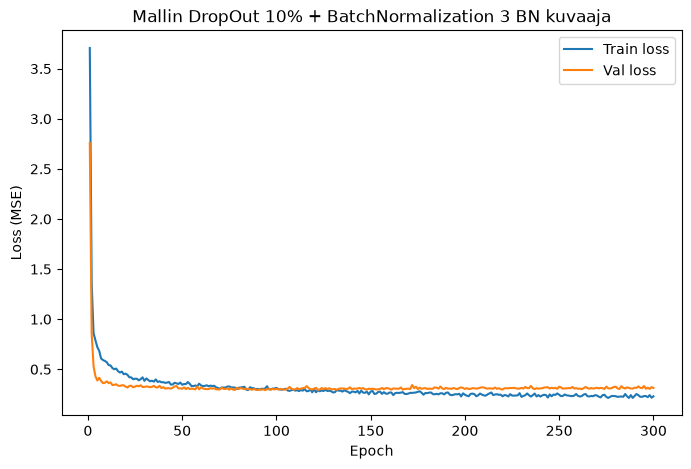

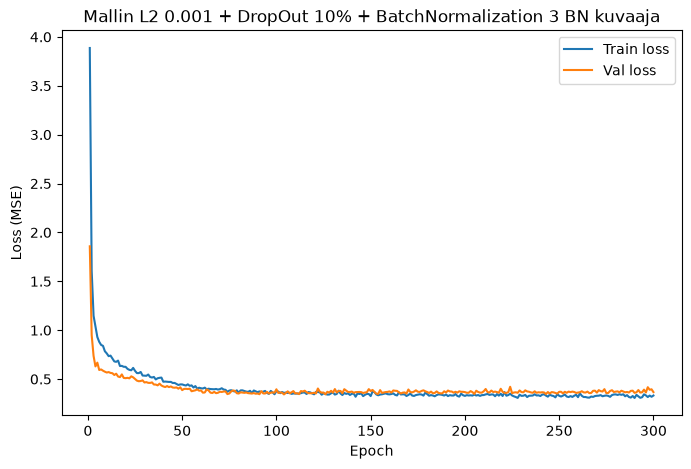

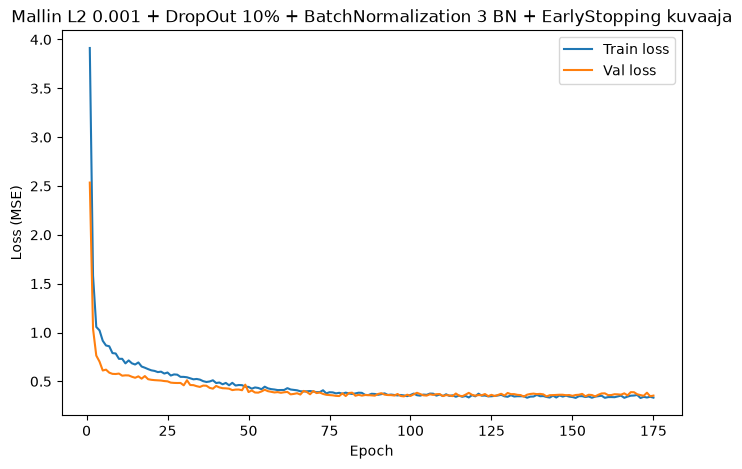

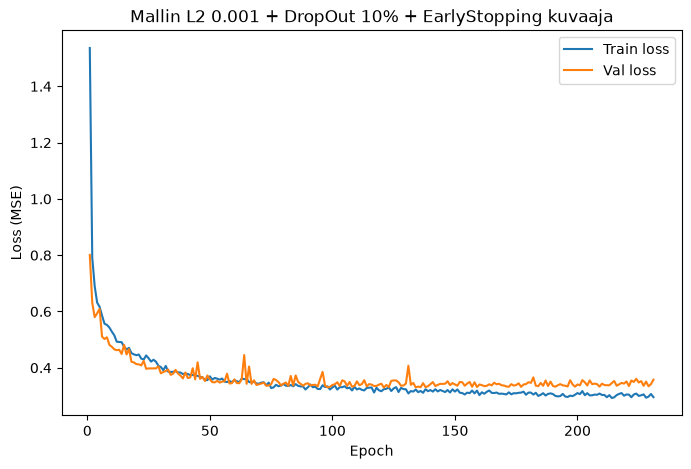

In [25]:
for model, history in histories.items():
    plt.figure(figsize=(8, 5))

    epochs = range(1, len(history.history['loss']) + 1)

    plt.plot(epochs, history.history['loss'], label='Train loss')
    plt.plot(epochs, history.history['val_loss'], label='Val loss')

    plt.legend()
    plt.title(f"Mallin {model} kuvaaja")
    plt.xlabel('Epoch')
    plt.ylabel('Loss (MSE)')
    plt.show()
    print("")

## Viimeiset EarlyStoppin kokeilun koulutuskäyrät

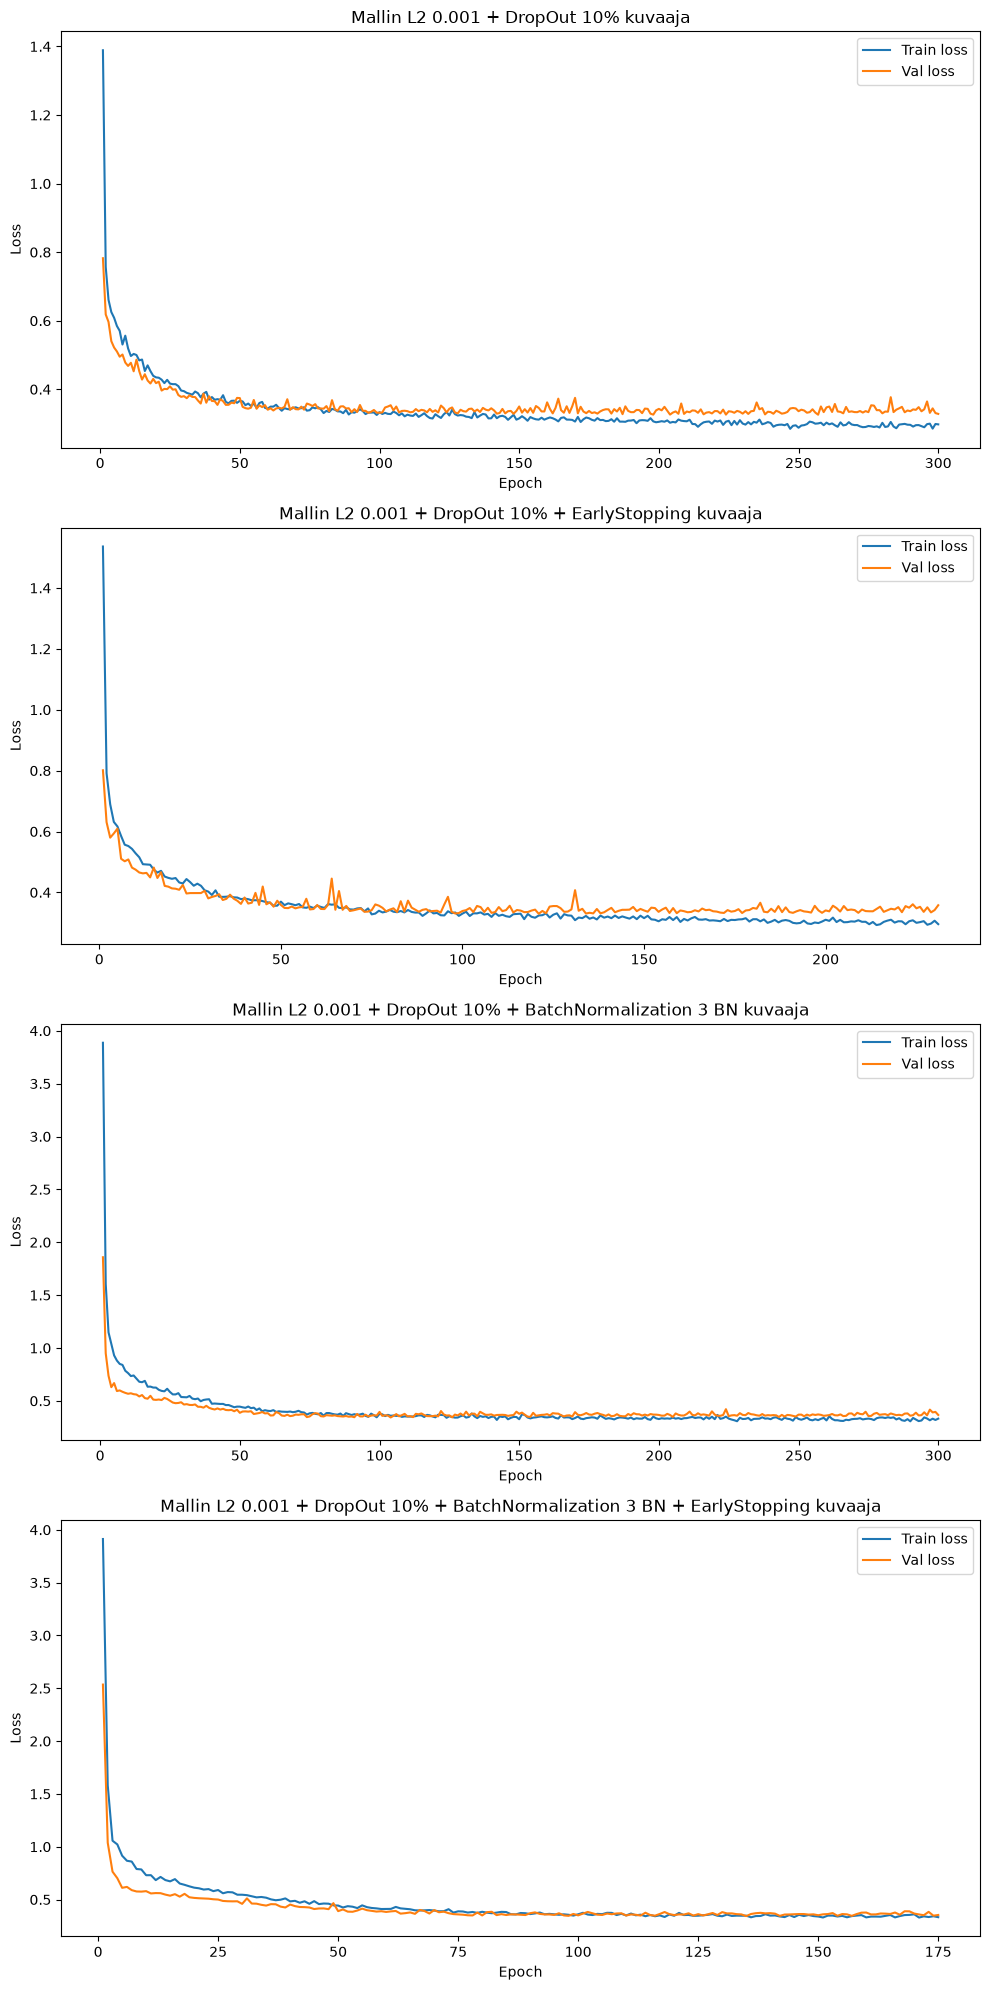

In [24]:
models = [
    ("L2 0.001 + DropOut 10%", "L2 0.001 + DropOut 10% + EarlyStopping"),
    ("L2 0.001 + DropOut 10% + BatchNormalization 3 BN", "L2 0.001 + DropOut 10% + BatchNormalization 3 BN + EarlyStopping")
]

fig, axes = plt.subplots(4, 1, figsize=(10, 20))

for i, (model, model_ES) in enumerate(models):
    for j, name in enumerate([model, model_ES]):
        history = histories[name]
        epochs = range(1, len(history.history['loss']) + 1)

        ax = axes[i * 2 + j]

        ax.plot(epochs, history.history['loss'], label='Train loss')
        ax.plot(epochs, history.history['val_loss'], label='Val loss')

        ax.legend()
        ax.set_title(f"Mallin {name} kuvaaja")
        ax.set_xlabel('Epoch')
        ax.set_ylabel('Loss')

plt.tight_layout()
plt.show()


## Kaikkien testattujen mallien arvot taulukossa järjestettynä parhaimman epochin val MAE:n mukaan

In [23]:
import pandas as pd
import numpy as np

results = []

for name, history in histories.items():
    h = history.history

    # Paras epoch validointi-MAE:n perusteella
    best_epoch = np.argmin(h["val_mae"])

    results.append({
        "Malli": name,
        "Paras epoch": best_epoch + 1,
        "Train MSE": h["loss"][best_epoch],
        "Val MSE": h["val_loss"][best_epoch],
        "Train MAE": h["mae"][best_epoch],
        "Val MAE": h["val_mae"][best_epoch],
        "Viimeinen Train MSE": h["loss"][-1],
        "Viimeinen Val MSE": h["val_loss"][-1],
        "Viimeinen Val MAE": h["val_mae"][-1]
    })

df_results = pd.DataFrame(results)

# Järjestetään parhaasta huonoimpaan MAE:n perusteella
df_results = df_results.sort_values("Val MAE")

display(df_results.round(4))


,Malli,Paras epoch,Train MSE,Val MSE,Train MAE,Val MAE,Viimeinen Train MSE,Viimeinen Val MSE,Viimeinen Val MAE
10,L2 0.001 + DropOut 10%,299,0.2988,0.3307,0.3535,0.3536,0.2977,0.3283,0.3600
2,L2 0.001,129,0.2649,0.3304,0.3267,0.3551,0.2281,0.3513,0.3763
4,Dropout 10%,82,0.2381,0.2868,0.3423,0.3577,0.1348,0.3240,0.3779
15,L2 0.001 + DropOut 10% + EarlyStopping,191,0.2999,0.3328,0.3562,0.3590,0.2957,0.3578,0.3763
6,Dropout 30%,251,0.2365,0.2898,0.3497,0.3609,0.2577,0.2999,0.3738
12,DropOut 10% + BatchNormalization 3 BN,237,0.2579,0.3021,0.3745,0.3615,0.2307,0.3140,0.3774
5,Dropout 20%,289,0.1857,0.3035,0.3110,0.3624,0.1860,0.3146,0.3829
13,L2 0.001 + DropOut 10% + BatchNormalization 3 BN,245,0.3403,0.3517,0.3926,0.3634,0.3318,0.3667,0.3802
11,L2 0.001 + BatchNormalization 3 BN,175,0.2899,0.3684,0.3599,0.3691,0.2675,0.3980,0.3894
14,L2 0.001 + DropOut 10% + BatchNormalization 3 ...,135,0.3475,0.3433,0.3981,0.3698,0.3332,0.3541,0.3738


## Viimeiset johtopäätökset ja huomiot

###  Johtopäätökset

Tehtävänannon mukaan parhaan val MAE arvon sai L2 0.001 + DropOut 10% malli. Sen käyrä hieman heittelee, mutta parhaaksi malliksi valitsisin itse L2 0.001 + DropOut 10% + EarlyStopping. Sen koulutusaika on nopeampi, sen ylioppiminen on lähes mitätöntä ja tarkkuus heikkeni vain vähän verrattuna ilman pysäytintä (0,0028 eli vain 280 dollaria). Earlystopppin takaa ettei malli yliopi, kun suurin merkki on val MAE:n nousu. Toinen merkittävä tekijä on val ja test MAE:n erotus. Siinä myös molemmat mallit pärjäsivät.

Paras malli MAE arvolla: **L2 0.001 + DropOut 10%**

Paras malli omasta mielestä: **L2 0.001 + DropOut 10% + EarlyStopping**

### Huomiot

Testit on tehty osissa ja siksi solujen järjestys voi heitellä. Halusin pitää kaikki kuvaajat ja kaikkien mallien koulutus historian vielä ylhäällä. 